# Trust Erosion Delta (ΔT): bank perception under general vs issue-specific news coverage

Outputs are from the original run (Kaggle, NVIDIA GPU, 18 Dec 2025). For readability, installation output and per-request scraping logs were trimmed, decorative log messages were renamed, and the plotly figures were re-rendered as static PNGs from the figure data embedded in the run output. No numeric output was changed. See `README.md` for the method and known limitations.


In [1]:
# ==========================================
# Step 1: Environment setup (pinned numpy/scipy for the transformer stack)
# ==========================================

import subprocess
import sys

def install_dependencies():
    print("Installing pinned dependencies...")
    packages = [
        "pip install --force-reinstall 'numpy<2.0.0' 'scipy<1.13.0'", 
        "pip install -U duckduckgo_search>=6.0.0 yfinance gnews requests lxml",
        "pip install -q torch transformers plotly tqdm accelerate"
    ]
    
    for cmd in packages:
        try:
            subprocess.check_call(cmd, shell=True)
        except subprocess.CalledProcessError as e:
            print(f"⚠️ Warning during install: {e}")
            
    print("Dependencies installed.")

install_dependencies()

# ------------------------------------------
# IMPORTS
# ------------------------------------------
import os
import time
import logging
import random
import pandas as pd
import numpy as np
import yfinance as yf
from gnews import GNews
from duckduckgo_search import DDGS
from tqdm.notebook import tqdm
import torch
import plotly.express as px
import plotly.graph_objects as go
from transformers import pipeline

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s | %(levelname)s | %(message)s',
    datefmt='%H:%M:%S'
)
logger = logging.getLogger("DataIntel")

device = 0 if torch.cuda.is_available() else -1
print(f"Python: {sys.version.split()[0]} | NumPy: {np.__version__}")
print(f"Device: {'GPU (CUDA)' if device==0 else 'CPU'}")

Python: 3.11.13 | NumPy: 1.26.4
Device: GPU (CUDA)


In [2]:
# ==========================================
# Step 2: Omni-Source Miner: multi-source news collection (General vs Targeted queries)
# ==========================================

!pip install ddgs # Ensure strict naming if env creates issues

class OmniMiner:
    def __init__(self):
        self.seen_urls = set()
        
    def _random_sleep(self, min_s=1, max_s=3):
        time.sleep(random.uniform(min_s, max_s))

    def fetch_gnews(self, query, bank, category, q_type, count=20):
        """Source A: Google News (High Reliability)"""
        data = []
        try:
            google_news = GNews(language='en', country='US', max_results=count, period='2y')
            results = google_news.get_news(query)
            
            for r in results:
                if r.get('url') not in self.seen_urls:
                    data.append({
                        'source': 'GNews',
                        'bank': bank,
                        'category': category,
                        'query_type': q_type, # General or Targeted
                        'search_term': query,
                        'title': r.get('title', '').split(' - ')[0],
                        'url': r.get('url'),
                        'published': r.get('published date')
                    })
                    self.seen_urls.add(r.get('url'))
            logger.info(f"[GNews] +{len(data)} records for '{query}'")
        except Exception as e:
            logger.error(f"[GNews] failed: {e}")
        return data

    def fetch_ddg(self, query, bank, category, q_type, count=20):
        """Source B: DuckDuckGo news (with retries)"""
        data = []
        retries = 3
        for i in range(retries):
            try:
                with DDGS() as ddgs:
                    # US-English news results
                    results = list(ddgs.news(keywords=query, region="us-en", max_results=count))
                    
                for r in results:
                    if r.get('url') not in self.seen_urls:
                        data.append({
                            'source': 'DuckDuckGo',
                            'bank': bank,
                            'category': category,
                            'query_type': q_type,
                            'search_term': query,
                            'title': r.get('title'),
                            'url': r.get('url'),
                            'published': r.get('date')
                        })
                        self.seen_urls.add(r.get('url'))
                
                if data:
                    logger.info(f"[DDG] +{len(data)} records for '{query}'")
                    break
            except Exception as e:
                logger.warning(f"[DDG] retry {i+1}/{retries}: {e}")
                self._random_sleep(2, 5)
        return data

    def fetch_yahoo_api(self, bank_name, ticker, category):
        """Source C: Yahoo Finance ticker news"""
        data = []
        if not ticker: return []
        
        try:
            yf_ticker = yf.Ticker(ticker)
            news_list = yf_ticker.news
            
            for item in news_list:
                link = item.get('link')
                if link not in self.seen_urls:
                    data.append({
                        'source': 'YahooFinance',
                        'bank': bank_name,
                        'category': category,
                        'query_type': 'General', # Yahoo Ticker news is usually general
                        'search_term': f"Ticker: {ticker}",
                        'title': item.get('title'),
                        'url': link,
                        'published': str(item.get('providerPublishTime'))
                    })
                    self.seen_urls.add(link)
            logger.info(f"[Yahoo] +{len(data)} records for {ticker}")
        except Exception as e:
            logger.error(f"[Yahoo] failed for {ticker}: {e}")
        return data

    def collect(self, targets, specific_topics):
        all_intel = []
        print("\nCollecting news: General (control) and Targeted (treatment) queries per bank...\n")
        
        for cat, banks in targets.items():
            for bank_name, ticker in banks.items():
                print(f"Collecting: {bank_name} ({ticker})")
                
                # --- GROUP A: CONTROL GROUP (GENERAL PERCEPTION) ---
                general_query = f'"{bank_name}" banking news'
                all_intel.extend(self.fetch_gnews(general_query, bank_name, cat, 'General', count=15))
                self._random_sleep()
                all_intel.extend(self.fetch_ddg(general_query, bank_name, cat, 'General', count=15))
                
                # Yahoo ticker news counts as General
                all_intel.extend(self.fetch_yahoo_api(bank_name, ticker, cat))
                
                # --- GROUP B: TREATMENT GROUP (SPECIFIC TOPICS) ---
                for topic in specific_topics:
                    specific_query = f'\"{bank_name}\" {topic}'
                    all_intel.extend(self.fetch_gnews(specific_query, bank_name, cat, 'Targeted', count=10))
                    self._random_sleep(0.5, 1.5)
                    all_intel.extend(self.fetch_ddg(specific_query, bank_name, cat, 'Targeted', count=10))
                
        return pd.DataFrame(all_intel)

TARGETS = {
    "Incumbents": {"JPMorgan Chase": "JPM", "Deutsche Bank": "DB"},
    "Challengers": {"Nubank": "NU", "Revolut": None}, 
    "Ethical": {"Triodos Bank": None, "Amalgamated Bank": "AMAL"}
}

TOPICS = [
    # --- Group 1: AI Paradox Indicators ---
    "AI innovation",      
    "AI transformation",  
    "AI bias",            
    "AI ethics",          
    
    # --- Group 2: Hypocrisy Stress Test ---
    "greenwashing",       
    "fossil fuel",        
    "data privacy"        
]

miner = OmniMiner()
df_raw = miner.collect(TARGETS, TOPICS)

print(f"\nTotal records: {len(df_raw)}")
print(df_raw['query_type'].value_counts()) # Check balance
df_raw.head()


Collecting: JPMorgan Chase (JPM)
Collecting: Deutsche Bank (DB)
Collecting: Nubank (NU)
Collecting: Revolut (None)
Collecting: Triodos Bank (None)
Collecting: Amalgamated Bank (AMAL)
Total records: 549
query_type
Targeted    378
General     171
Name: count, dtype: int64


,source,bank,category,query_type,search_term,title,url,published
0,GNews,JPMorgan Chase,Incumbents,General,"""JPMorgan Chase"" banking news",JPMorgan Chase to launch deposit token,https://news.google.com/rss/articles/CBMihgFBV...,"Wed, 18 Jun 2025 07:00:00 GMT"
1,GNews,JPMorgan Chase,Incumbents,General,"""JPMorgan Chase"" banking news",Inside Chase's Aggressive Consumer Strategy: M...,https://news.google.com/rss/articles/CBMixwFBV...,"Fri, 23 May 2025 07:00:00 GMT"
2,GNews,JPMorgan Chase,Incumbents,General,"""JPMorgan Chase"" banking news",JPMorgan Chase to Charge Data Aggregators for ...,https://news.google.com/rss/articles/CBMivwFBV...,"Mon, 14 Jul 2025 07:00:00 GMT"
3,GNews,JPMorgan Chase,Incumbents,General,"""JPMorgan Chase"" banking news",How JPMorgan's embrace of AI could change bank...,https://news.google.com/rss/articles/CBMigwFBV...,"Wed, 19 Nov 2025 08:00:00 GMT"
4,GNews,JPMorgan Chase,Incumbents,General,"""JPMorgan Chase"" banking news",JPMorgan Chase adds to US defection from Net-Z...,https://news.google.com/rss/articles/CBMiswFBV...,"Tue, 07 Jan 2025 08:00:00 GMT"


In [5]:
# ==========================================
# Step 3: Coverage audit and targeted back-fill
# ==========================================

def augment_weak_spots(df, miner, min_threshold=30):
    print(f"Coverage audit (floor: {min_threshold} records per bank × search term)...")
    
    audit = df[df['query_type'] == 'Targeted'].groupby(['category', 'bank', 'search_term']).size().reset_index(name='count')
    
    weak_spots = audit[audit['count'] < min_threshold]
    
    if weak_spots.empty:
        print("All targeted cells meet the floor.")
        return df
    
    print(f"Found {len(weak_spots)} under-covered cells. Back-filling...\n")
    
    new_intel = []
    
    for index, row in weak_spots.iterrows():
        bank = row['bank']
        category = row['category']
        term = row['search_term'] # e.g., '"Triodos Bank" AI ethics'
        current_count = row['count']
        deficit = min_threshold - current_count
        
        print(f"   Back-filling: {bank} | '{term}' (short by {deficit})")
        
        try:
            loose_term = term.replace('"', '') 
            new_intel.extend(miner.fetch_gnews(loose_term, bank, category, 'Targeted', count=deficit + 10))
        except:
            pass
            
        miner._random_sleep(1, 2)
        
        # DuckDuckGo fetch
        try:
            new_intel.extend(miner.fetch_ddg(term, bank, category, 'Targeted', count=deficit + 15))
        except:
            pass

    if new_intel:
        df_new = pd.DataFrame(new_intel)
        print(f"\nRetrieved {len(df_new)} new records.")
        
        df_combined = pd.concat([df, df_new], ignore_index=True)

        before_dedup = len(df_combined)
        df_combined = df_combined.drop_duplicates(subset=['url'], keep='first')
        after_dedup = len(df_combined)
        
        print(f"Deduplication by URL: removed {before_dedup - after_dedup} duplicates.")
        print(f"Dataset: {len(df)} -> {len(df_combined)} records.")
        
        return df_combined
    else:
        print("No new unique records found; these topics may have little coverage.")
        return df

df_augmented = augment_weak_spots(df_raw, miner, min_threshold=30)

print("\nPost back-fill coverage (thinnest search terms):")
print(df_augmented[df_augmented['query_type'] == 'Targeted']['search_term'].value_counts().tail(10))

df_raw = df_augmented

Coverage audit (floor: 30 records per bank × search term)...
Found 38 under-covered cells. Back-filling...

   Back-filling: Nubank | '"Nubank" AI bias' (short by 20)
   Back-filling: Nubank | '"Nubank" AI ethics' (short by 24)
   Back-filling: Nubank | '"Nubank" AI innovation' (short by 13)
   Back-filling: Nubank | '"Nubank" AI transformation' (short by 19)
   Back-filling: Nubank | '"Nubank" data privacy' (short by 17)
   Back-filling: Nubank | '"Nubank" greenwashing' (short by 21)
   Back-filling: Revolut | '"Revolut" AI bias' (short by 20)
   Back-filling: Revolut | '"Revolut" AI ethics' (short by 21)
   Back-filling: Revolut | '"Revolut" AI innovation' (short by 10)
   Back-filling: Revolut | '"Revolut" AI transformation' (short by 16)
   Back-filling: Revolut | '"Revolut" data privacy' (short by 11)
   Back-filling: Revolut | '"Revolut" fossil fuel' (short by 18)
   Back-filling: Revolut | '"Revolut" greenwashing' (short by 23)
   Back-filling: Amalgamated Bank | '"Amalgamated B

In [6]:
# ==========================================
# Step 4: Scoring: FinBERT sentiment + zero-shot trust index
# ==========================================
# Methodology Upgrade v2:
# 1. Sentiment: Now uses "Soft Probability Weighted Score" (P_pos - P_neg)
#    instead of "Hard Labeling". Captures subtle nuances even in neutral news.
# 2. Trustworthiness: Zero-Shot inference as before.

from transformers import pipeline
from tqdm.notebook import tqdm
import torch

def analyze_intelligence_soft(df):
    if df.empty: return df

    device = 0 if torch.cuda.is_available() else -1
    
    # --- MODEL 1: FinBERT (Financial Sentiment) ---
    print("Loading model 1: FinBERT (ProsusAI/finbert), soft sentiment scoring...")
    try:
        sent_pipe = pipeline("text-classification", model="ProsusAI/finbert", device=device, top_k=None)
    except Exception as e:
        print(f"GPU error, falling back to CPU: {e}")
        sent_pipe = pipeline("text-classification", model="ProsusAI/finbert", device=-1, top_k=None)

    # --- MODEL 2: Zero-Shot (Trust/Ethics) ---
    print("Loading model 2: BART-large-MNLI, zero-shot trust index...")
    zsc_pipe = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=device)

    print("Scoring headlines...")
    
    titles = df['title'].astype(str).tolist()
 
    print("   ...Computing Weighted Sentiment Scores")
    final_sentiments = []
    batch_size = 16 
    
    for i in tqdm(range(0, len(titles), batch_size), desc="FinBERT"):
        batch = titles[i:i+batch_size]
        res = sent_pipe(batch, truncation=True, max_length=128)
        
        for r in res:
            scores = {item['label']: item['score'] for item in r}
            
            weighted_score = scores.get('positive', 0) - scores.get('negative', 0)
            final_sentiments.append(weighted_score)
    
    trust_labels = ["ethics integrity reliability", "scandal fraud controversy risk"]
    print("   ...Computing Trust Archetypes (Zero-Shot)")
    trust_scores = []
    
    for i in tqdm(range(0, len(titles), batch_size), desc="Zero-Shot"):
        batch = titles[i:i+batch_size]
        res = zsc_pipe(batch, candidate_labels=trust_labels, multi_label=False)
        for r in res:
            ethic_idx = r['labels'].index(trust_labels[0])
            risk_idx = r['labels'].index(trust_labels[1])
            
            # Trust Score = P(Ethics) - P(Risk)
            trust_scores.append(r['scores'][ethic_idx] - r['scores'][risk_idx])

    df['ai_sentiment'] = final_sentiments
    df['ai_trust_index'] = trust_scores
    
    return df

df_analyzed = analyze_intelligence_soft(df_raw)
print("Scoring complete.")

df_analyzed[['title', 'ai_sentiment', 'ai_trust_index']].sample(5)

Loading model 1: FinBERT (ProsusAI/finbert), soft sentiment scoring...


Device set to use cuda:0


Loading model 2: BART-large-MNLI, zero-shot trust index...


Device set to use cuda:0


Scoring headlines...
   ...Computing Weighted Sentiment Scores
   ...Computing Trust Archetypes (Zero-Shot)
Scoring complete.


,title,ai_sentiment,ai_trust_index
361,Fintech firm Revolut Scoops Up AI Travel Agent...,0.047921,0.407557
237,Watch Nubank’s Junqueira on Disrupting the Ban...,-0.505479,-0.092461
235,Nubank and Mastercard exclusive study reveals ...,0.806942,0.454271
319,Nubank: Driving Financial Services Competition...,0.287897,0.778390
208,Banking trends: Deutsche Bank leads surge in f...,0.872563,0.002180


Computing ΔT per bank...

H2: Trust Erosion Delta by bank (General − Targeted trust; higher = larger drop)


Δ Trust Erosion (Higher is Worse)  \
category    bank                                                  
Incumbents  Deutsche Bank                              0.398226   
Challengers Revolut                                    0.154390   
Ethical     Triodos Bank                               0.143767   
            Amalgamated Bank                           0.133381   
Incumbents  JPMorgan Chase                             0.084500   
Challengers Nubank                                    -0.122666   

                              Δ Sentiment Impact  
category    bank                                  
Incumbents  Deutsche Bank              -0.345511  
Challengers Revolut                     0.022130  
Ethical     Triodos Bank                0.004948  
            Amalgamated Bank           -0.250109  
Incumbents  JPMorgan Chase             -0.099893  
Challengers Nubank                      0.129162

H1: AI efficiency vs AI ethics coverage, by bank category


ai_trust_index  ai_sentiment
category    ai_context                                        
Challengers AI Risk (Ethics)            0.409529      0.199619
            AI Tech (Efficiency)        0.467014      0.309912
Ethical     AI Risk (Ethics)            0.924735      0.304793
            AI Tech (Efficiency)        0.320665      0.175756
Incumbents  AI Risk (Ethics)            0.371131     -0.016305
            AI Tech (Efficiency)        0.467902      0.173499

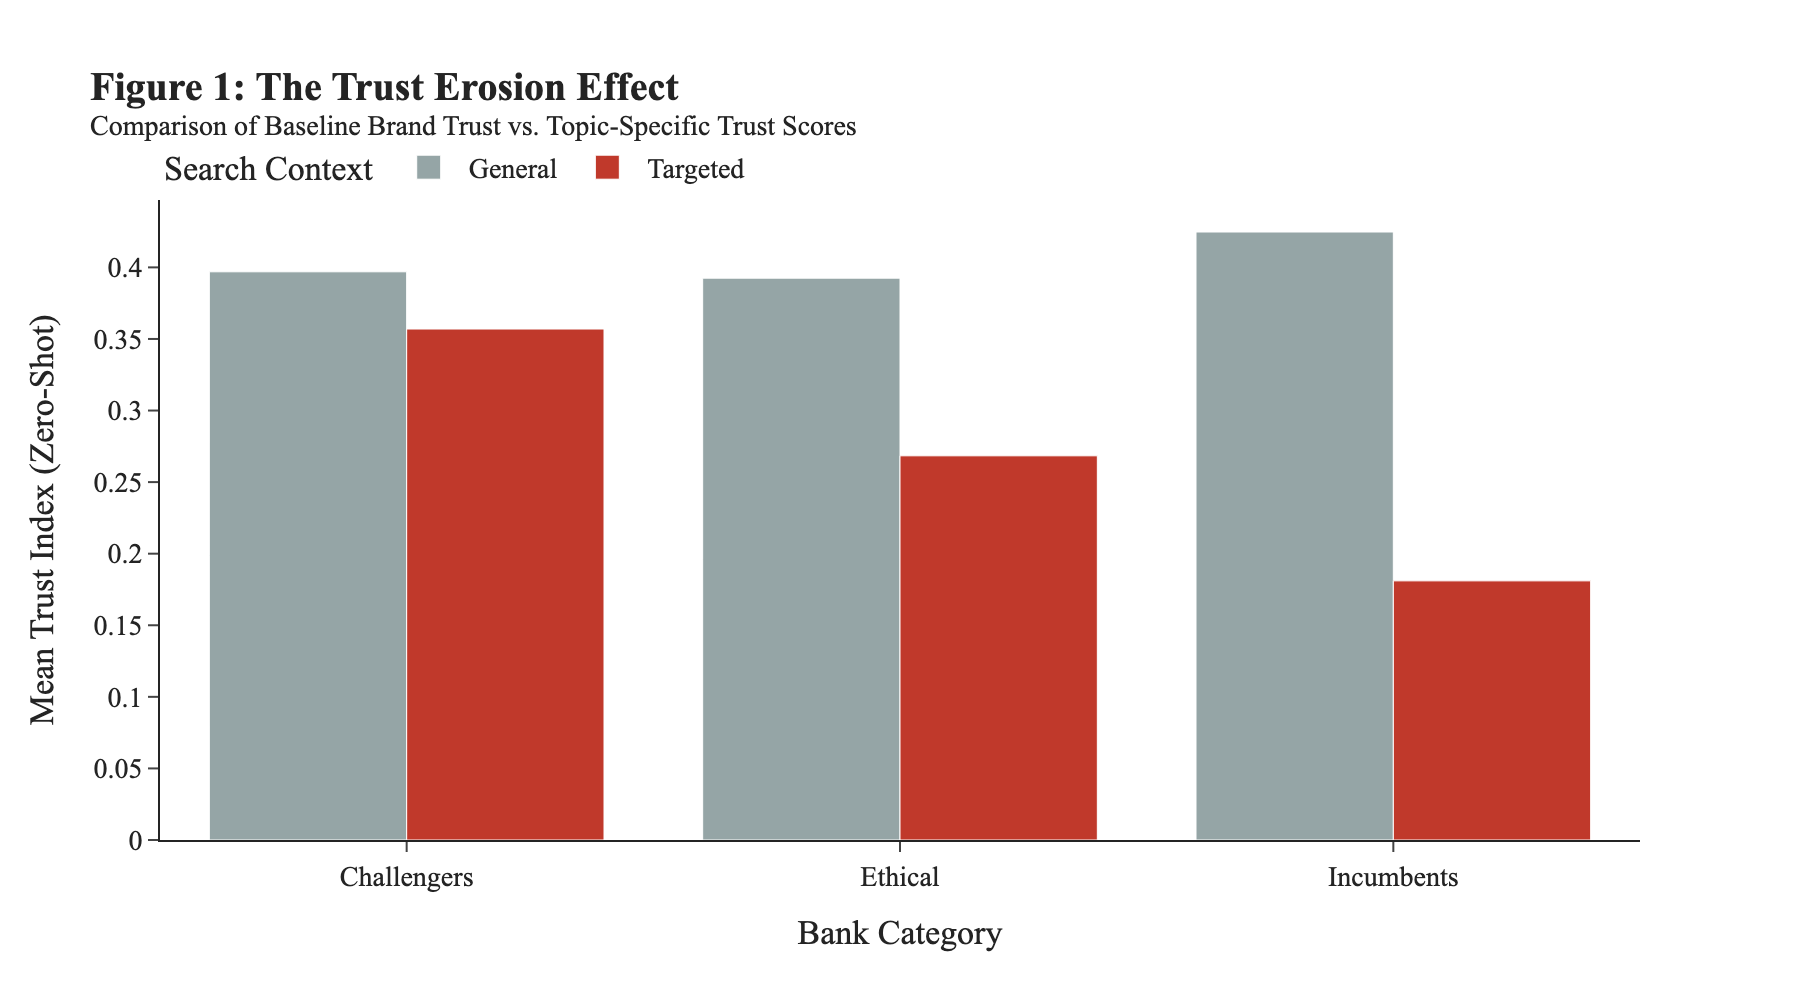

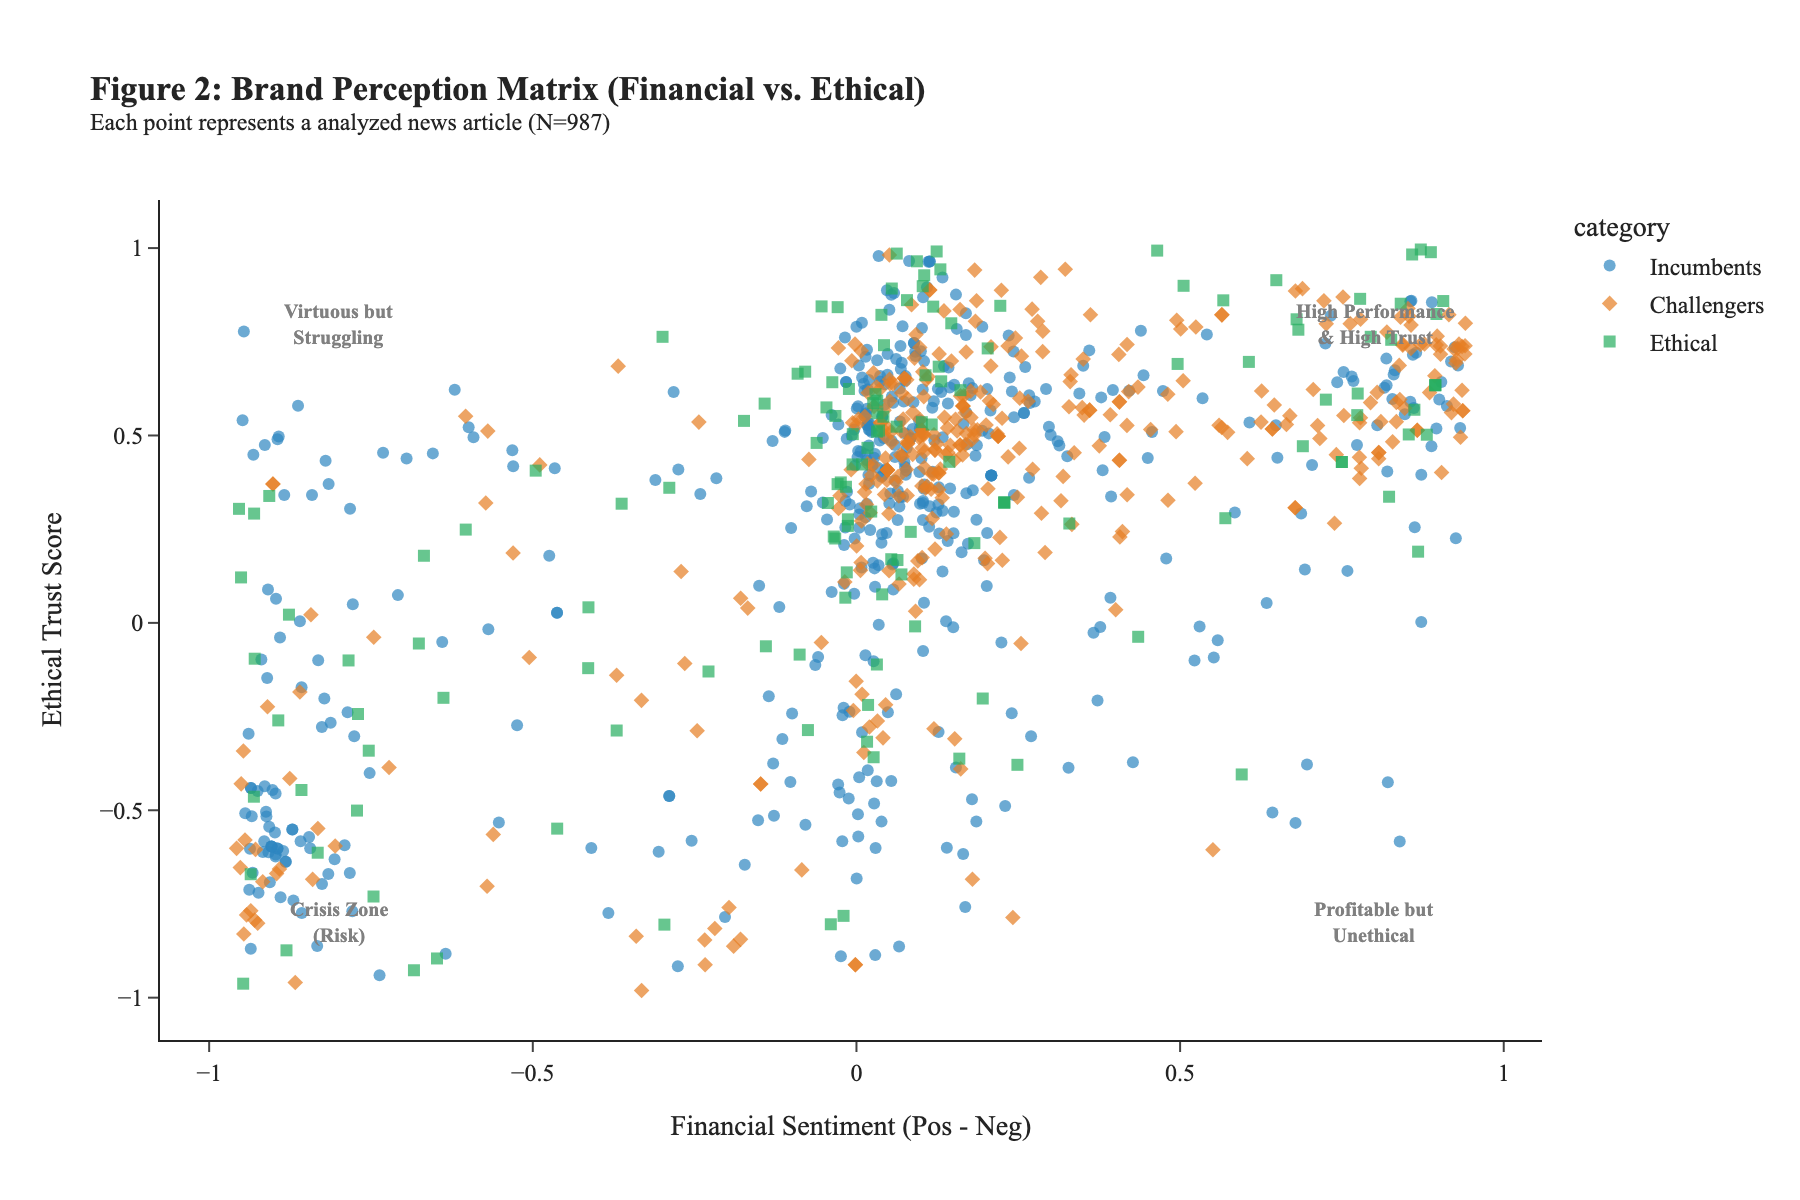

In [7]:
# ==========================================
# Step 5: Trust Erosion Delta (ΔT) and figures
# ==========================================

def calculate_academic_metrics(df):
    print("Computing ΔT per bank...")
    
    # Pivot Table: Bank x Query Type (General vs Targeted)
    pivot = df.groupby(['category', 'bank', 'query_type'])[['ai_trust_index', 'ai_sentiment']].mean().unstack()
    
    pivot['Trust_Erosion_Delta'] = pivot[('ai_trust_index', 'General')] - pivot[('ai_trust_index', 'Targeted')]
    pivot['Sentiment_Impact'] = pivot[('ai_sentiment', 'Targeted')] - pivot[('ai_sentiment', 'General')]
    
    metrics = pivot[['Trust_Erosion_Delta', 'Sentiment_Impact']].copy()
    metrics.columns = ['Δ Trust Erosion (Higher is Worse)', 'Δ Sentiment Impact']
    metrics = metrics.sort_values('Δ Trust Erosion (Higher is Worse)', ascending=False)
    
    print("\nH2: Trust Erosion Delta by bank (General − Targeted trust; higher = larger drop)")
    display(metrics)
    
    # Metric 2: AI Paradox (Efficiency vs Ethics)
    ai_df = df[df['search_term'].str.contains("AI", case=False, na=False)].copy()
    if not ai_df.empty:
        # Simple classifier for AI sub-topics
        def classify_ai_topic(term):
            if any(x in term.lower() for x in ['innovation', 'transformation']): return 'AI Tech (Efficiency)'
            if any(x in term.lower() for x in ['bias', 'ethics']): return 'AI Risk (Ethics)'
            return 'Other AI'
            
        ai_df['ai_context'] = ai_df['search_term'].apply(classify_ai_topic)
        ai_summary = ai_df.groupby(['category', 'ai_context'])[['ai_trust_index', 'ai_sentiment']].mean()
        
        print("\nH1: AI efficiency vs AI ethics coverage, by bank category")
        display(ai_summary)
    else:
        print("\nNo AI-specific records found; update TOPICS and re-run collection.")

    return metrics

def plot_academic_results(df):
    avg_scores = df.groupby(['category', 'query_type'])['ai_trust_index'].mean().reset_index()
    
    fig1 = px.bar(
        avg_scores, 
        x="category", 
        y="ai_trust_index", 
        color="query_type", 
        barmode="group",
        title="<b>Figure 1: The Trust Erosion Effect</b><br><sup>Comparison of Baseline Brand Trust vs. Topic-Specific Trust Scores</sup>",
        labels={"ai_trust_index": "Mean Trust Index (Zero-Shot)", "category": "Bank Category"},
        color_discrete_map={"General": "#95A5A6", "Targeted": "#C0392B"}, # Grey for baseline, Red for targeted risk
        template="simple_white", 
        height=500
    )
    
    fig1.update_layout(
        font=dict(family="Times New Roman", size=14), 
        legend=dict(title="Search Context", y=1.1, orientation="h"),
        bargap=0.2
    )
    fig1.show()

    # Figure 2: perception matrix (scatter)
    fig2 = px.scatter(
        df, 
        x="ai_sentiment", 
        y="ai_trust_index", 
        color="category", 
        symbol="category", 
        size_max=10,
        opacity=0.7,
        title="<b>Figure 2: Brand Perception Matrix (Financial vs. Ethical)</b><br><sup>Each point represents a analyzed news article (N={})</sup>".format(len(df)),
        labels={"ai_sentiment": "Financial Sentiment (Pos - Neg)", "ai_trust_index": "Ethical Trust Score"},
        color_discrete_map={"Incumbents": "#2E86C1", "Challengers": "#E67E22", "Ethical": "#27AE60"},
        template="simple_white",
        height=600
    )
    
    fig2.add_hline(y=0, line_dash="dash", line_color="gray", opacity=0.5)
    fig2.add_vline(x=0, line_dash="dash", line_color="gray", opacity=0.5)
    
    annotations = [
        dict(x=0.8, y=0.8, text="<b>High Performance<br>& High Trust</b>", showarrow=False, font=dict(size=10, color="gray")),
        dict(x=0.8, y=-0.8, text="<b>Profitable but<br>Unethical</b>", showarrow=False, font=dict(size=10, color="gray")),
        dict(x=-0.8, y=-0.8, text="<b>Crisis Zone<br>(Risk)</b>", showarrow=False, font=dict(size=10, color="gray")),
        dict(x=-0.8, y=0.8, text="<b>Virtuous but<br>Struggling</b>", showarrow=False, font=dict(size=10, color="gray"))
    ]
    fig2.update_layout(annotations=annotations, font=dict(family="Times New Roman", size=12))
    
    fig2.show()

metrics = calculate_academic_metrics(df_analyzed)
plot_academic_results(df_analyzed)